## Downloading data from kaggle

In [18]:
!pip install opendatasets legacy-cgi --quiet
import opendatasets as od
od.download("https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia")

Skipping, found downloaded files in "./chest-xray-pneumonia" (use force=True to force download)


## Importing libraries

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
import os
from PIL import Image # used to read the images from the directory
import torch
from torch import nn
from torch.optim import Adam
import torchvision.transforms as transforms # used to modify and preprocess all the images
from torch.utils.data import Dataset, DataLoader


In [20]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## loading data to dataframe

In [21]:

import os
import pandas as pd

image_path = []
labels = []

# Loop through train, test, and val
for split in ["train", "test", "val"]:
    split_path = os.path.join("/content/chest-xray-pneumonia/chest_xray/", split)

    # Loop through NORMAL and PNEUMONIA
    for label in ["NORMAL", "PNEUMONIA"]:
        label_path = os.path.join(split_path, label)

        if os.path.isdir(label_path):
            for image in os.listdir(label_path):
                if image.lower().endswith((".jpg", ".jpeg", ".png")):
                    image_path.append(os.path.join(label_path, image))
                    labels.append(label)

df = pd.DataFrame({"image_paths": image_path, "labels": labels})

df.head()


,image_paths,labels
0,/content/chest-xray-pneumonia/chest_xray/train...,NORMAL
1,/content/chest-xray-pneumonia/chest_xray/train...,NORMAL
2,/content/chest-xray-pneumonia/chest_xray/train...,NORMAL
3,/content/chest-xray-pneumonia/chest_xray/train...,NORMAL
4,/content/chest-xray-pneumonia/chest_xray/train...,NORMAL


In [22]:
print(df["labels"].value_counts())

labels
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64


## Splitting data
- Training: 70% (of 100% data)
- Validation: 15% (50% of 30% data)
- Testing: 15% (50% of 30% data)

In [23]:
# create train_data of 70% of the data
train_data = df.sample(frac=0.7, random_state=7)

# drop training rows to get the remaining 30% for the remaining data
remaining = df.drop(train_data.index)

# split the remaining 30% in half (50%) to get Test and Validation
test_data = remaining.sample(frac=0.5, random_state=7)
validation_data = remaining.drop(test_data.index)

print(f"The original dataset has {len(df)} rows")
print(f"The training dataset has {len(train_data)} rows which is 70% of the data")
print(f"The validation dataset has {len(validation_data)} rows which is 15% of the data")
print(f"The testing dataset has {len(test_data)} rows which is 15% of the data")

The original dataset has 5856 rows
The training dataset has 4099 rows which is 70% of the data
The validation dataset has 879 rows which is 15% of the data
The testing dataset has 878 rows which is 15% of the data


## Label encoding

In [24]:
label_encoder = LabelEncoder()
label_encoder.fit(df['labels'])

LabelEncoder()

## Image preprocessing

In [25]:
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])


## Custom Dataset Class

In [26]:
class CustomXRayDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.labels = torch.tensor(label_encoder.transform(self.dataframe["labels"]), dtype=torch.long)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx]["image_paths"]
        label = self.labels[idx]

        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


## Creating Dataset Objects


In [27]:
train_dataset = CustomXRayDataset(dataframe=train_data, transform=train_transform)
test_dataset = CustomXRayDataset(dataframe=test_data, transform=transform)
validation_dataset = CustomXRayDataset(dataframe=validation_data, transform=transform)

## Visualizing images

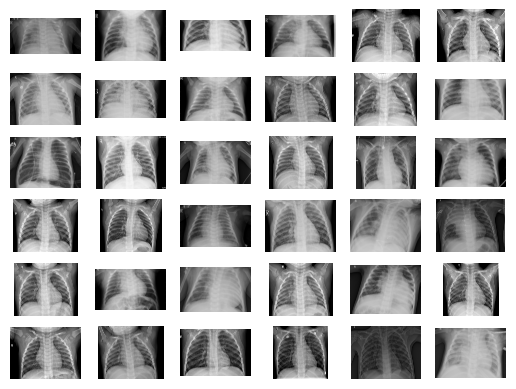

In [28]:
n_rows = 6
n_cols = 6
f, axarr = plt.subplots(n_rows, n_cols)
for row in range(n_rows):
    for col in range(n_cols):
      image = Image.open(df.sample(n = 1)['image_paths'].iloc[0]).convert("RGB")
      axarr[row, col].imshow(image)
      axarr[row, col].axis('off')

plt.show()

In [29]:
learning_rate = 1e-4
batch_size = 32
epochs = 25


In [30]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=True)

## Model Training

In [31]:
class XRayClassificationModel(nn.Module):
    def __init__(self, dropout_rate=0.3):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 32 * 32, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = XRayClassificationModel().to(device)

## Model Creation

In [32]:
from torchsummary import summary
summary(model, input_size = (3, 128, 128))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
              ReLU-2         [-1, 32, 128, 128]               0
         MaxPool2d-3           [-1, 32, 64, 64]               0
            Conv2d-4           [-1, 64, 64, 64]          18,496
              ReLU-5           [-1, 64, 64, 64]               0
         MaxPool2d-6           [-1, 64, 32, 32]               0
           Flatten-7                [-1, 65536]               0
            Linear-8                   [-1, 64]       4,194,368
              ReLU-9                   [-1, 64]               0
          Dropout-10                   [-1, 64]               0
           Linear-11                    [-1, 2]             130
Total params: 4,213,890
Trainable params: 4,213,890
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.19
Forw

In [33]:
class_counts = train_data["labels"].value_counts()
class_weights = torch.tensor(len(train_data) / (2 * class_counts[label_encoder.classes_].values),dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = Adam(model.parameters(), lr=learning_rate)

## Training Loop

In [34]:
total_training_loss = []
total_validation_loss = []
total_training_accuracy = []
total_validation_accuracy = []

for epoch in range(epochs):

    total_train_loss = 0
    total_train_accuracy = 0
    total_val_loss = 0
    total_val_accuracy = 0

    # training
    model.train()

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        prediction = model(images)
        loss = criterion(prediction, labels)

        total_train_loss += loss.item()

        accuracy = (torch.argmax(prediction, dim=1) == labels).sum().item()
        total_train_accuracy += accuracy

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # validation
    model.eval()

    with torch.no_grad():

        for images, labels in validation_loader:

            images = images.to(device)
            labels = labels.to(device)

            prediction = model(images)
            loss = criterion(prediction, labels)

            total_val_loss += loss.item()

            accuracy = (torch.argmax(prediction, dim=1) == labels).sum().item()
            total_val_accuracy += accuracy

    # average metrics
    train_loss = total_train_loss / len(train_loader)
    val_loss = total_val_loss / len(validation_loader)

    train_accuracy = total_train_accuracy / len(train_dataset) * 100
    val_accuracy = total_val_accuracy / len(validation_dataset) * 100

    # store metrics
    total_training_loss.append(train_loss)
    total_validation_loss.append(val_loss)
    total_training_accuracy.append(train_accuracy)
    total_validation_accuracy.append(val_accuracy)

    print(f"| Epoch: {epoch + 1} | Train Accuracy: {train_accuracy:.2f}% | Train Loss: {train_loss:.4f} | Validation Accuracy: {val_accuracy:.2f}% | Validation Loss: {val_loss:.4f} |")
    print("-" * 114)

| Epoch: 1 | Train Accuracy: 83.87% | Train Loss: 0.3611 | Validation Accuracy: 88.96% | Validation Loss: 0.2396 |
------------------------------------------------------------------------------------------------------------------
| Epoch: 2 | Train Accuracy: 90.56% | Train Loss: 0.2401 | Validation Accuracy: 87.94% | Validation Loss: 0.2417 |
------------------------------------------------------------------------------------------------------------------
| Epoch: 3 | Train Accuracy: 91.97% | Train Loss: 0.2063 | Validation Accuracy: 94.20% | Validation Loss: 0.1868 |
------------------------------------------------------------------------------------------------------------------
| Epoch: 4 | Train Accuracy: 92.36% | Train Loss: 0.2062 | Validation Accuracy: 91.81% | Validation Loss: 0.1800 |
------------------------------------------------------------------------------------------------------------------
| Epoch: 5 | Train Accuracy: 92.63% | Train Loss: 0.1872 | Validation Accuracy: 

## Model Testing

In [43]:
model.eval()

total_test_loss = 0
total_test_accuracy = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        prediction = model(images)

        loss = criterion(prediction, labels)
        total_test_loss += loss.item()

        predicted = torch.argmax(prediction, dim=1)
        correct = (predicted == labels).sum().item()
        total_test_accuracy += correct

test_loss = total_test_loss / len(test_loader)
test_accuracy = total_test_accuracy / len(test_loader.dataset) * 100

print("-" * 45)
print(f"| Test Accuracy: {test_accuracy:.2f}% | Test Loss: {test_loss:.4f} |")
print("-" * 45)

---------------------------------------------
| Test Accuracy: 94.31% | Test Loss: 0.1380 |
---------------------------------------------


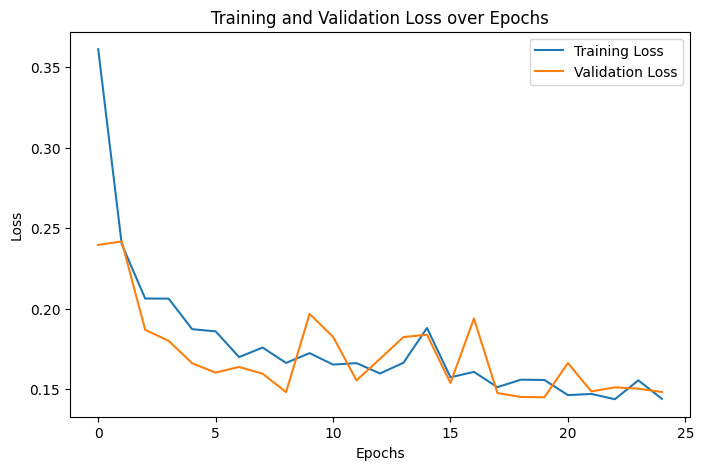

In [44]:
plt.figure(figsize=(8, 5))
plt.plot(total_training_loss, label='Training Loss')
plt.plot(total_validation_loss, label='Validation Loss')
plt.title('Training and Validation Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

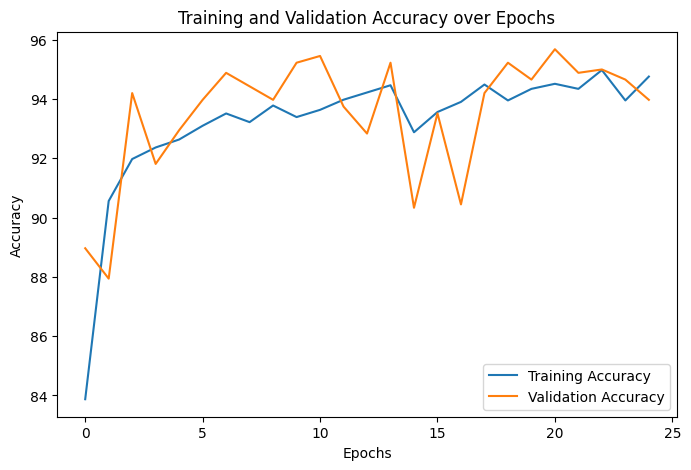

In [45]:
plt.figure(figsize=(8, 5))
plt.plot(total_training_accuracy, label='Training Accuracy')
plt.plot(total_validation_accuracy, label='Validation Accuracy')
plt.title('Training and Validation Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

## Model Testing

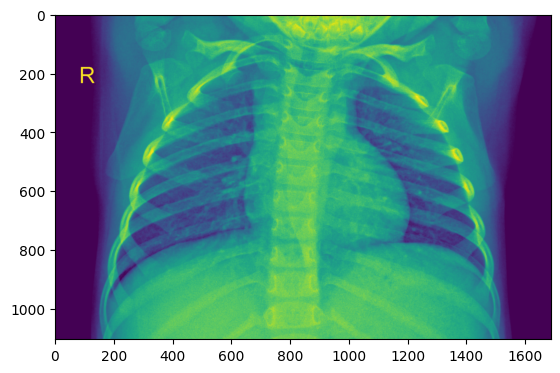


Prediction: 

['NORMAL']


In [48]:
def predict_image(image_path):
  image = Image.open(image_path).convert('RGB')
  image = transform(image).to(device)

  output = model(image.unsqueeze(0))
  output = torch.argmax(output, axis = 1).item()
  return label_encoder.inverse_transform([output])

## Get a sample image from the dataset
sample_image_path = df.sample(n=1)['image_paths'].iloc[0]

## Visualize the image
image = Image.open(sample_image_path)
plt.imshow(image)
plt.show()


## Predict
print()
print("Prediction: \n")
prediction = predict_image(sample_image_path)
print(prediction)

In [49]:
# saves the model for deployment
torch.save(model.state_dict(), 'xray_classifier.pth')
print("Model successfully saved to xray_classifier.pth")

Model successfully saved to xray_classifier.pth
